In [2]:
import pandas as pd

# Charger le fichier CSV
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Afficher les 5 premières lignes
print(df.head())

# Afficher les informations générales sur le dataset (types de colonnes, valeurs manquantes...)
print(df.info())

# Afficher le nombre de lignes et de colonnes
print(df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [3]:
# Vérifier s'il y a des valeurs manquantes
print(df.isnull().sum())

# Convertir TotalCharges en numérique (les erreurs deviennent NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Vérifier à nouveau les valeurs manquantes après conversion
print("\nValeurs manquantes après conversion de TotalCharges :")
print(df.isnull().sum())

# Voir la distribution de la variable cible (Churn)
print("\nDistribution de Churn :")
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Valeurs manquantes après conversion de TotalCharges :
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn     

In [4]:
# Supprimer les lignes qui ont des valeurs manquantes
df = df.dropna()

# Supprimer la colonne customerID (elle n'est pas utile pour le modèle)
df = df.drop('customerID', axis=1)

# Vérifier la nouvelle taille du dataset
print("Taille du dataset après nettoyage :", df.shape)

# Vérifier qu'il n'y a plus de valeurs manquantes
print("\nValeurs manquantes restantes :")
print(df.isnull().sum().sum())

Taille du dataset après nettoyage : (7032, 20)

Valeurs manquantes restantes :
0


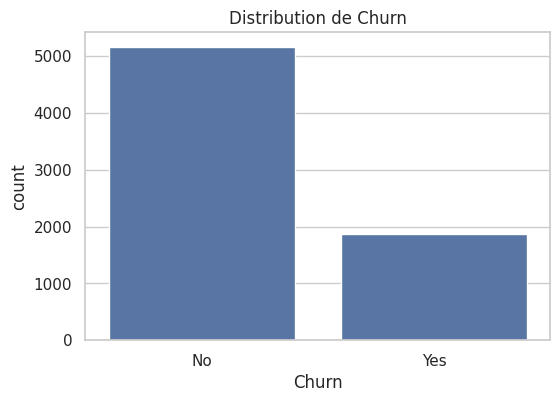

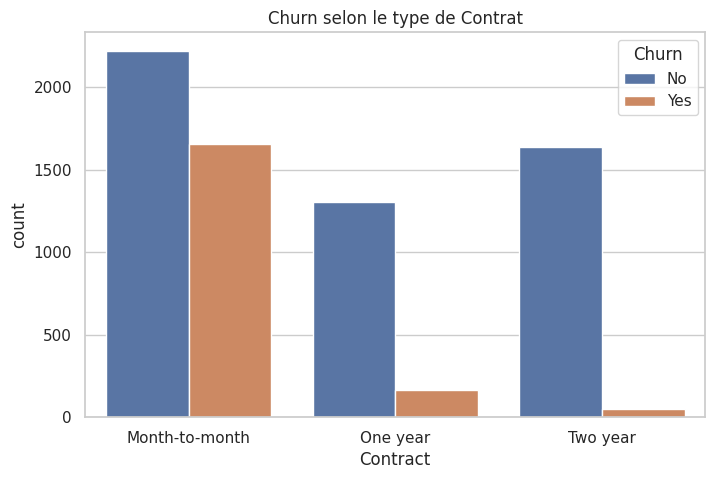

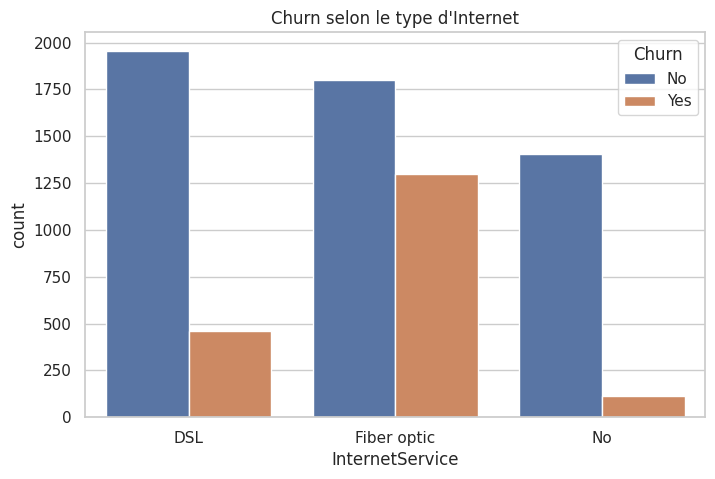

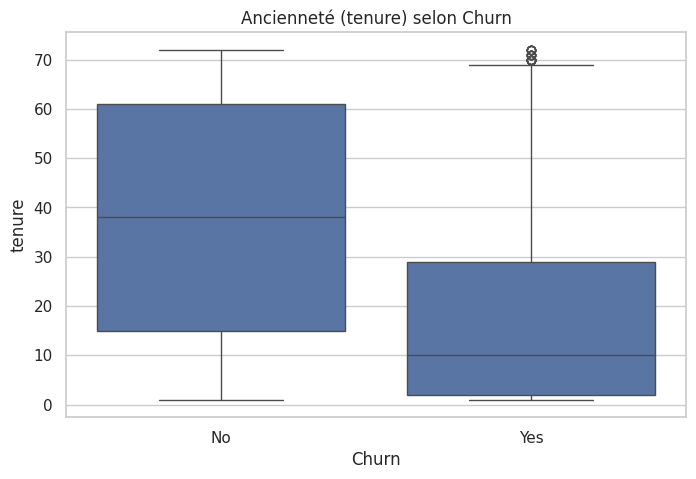

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Style des graphiques
sns.set(style="whitegrid")

# 1. Distribution de Churn
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df)
plt.title("Distribution de Churn")
plt.show()

# 2. Churn selon le type de contrat
plt.figure(figsize=(8,5))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title("Churn selon le type de Contrat")
plt.show()

# 3. Churn selon le service Internet
plt.figure(figsize=(8,5))
sns.countplot(x='InternetService', hue='Churn', data=df)
plt.title("Churn selon le type d'Internet")
plt.show()

# 4. Boxplot de tenure selon Churn
plt.figure(figsize=(8,5))
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title("Ancienneté (tenure) selon Churn")
plt.show()

In [6]:
# Séparer les features (X) et la cible (y)
X = df.drop('Churn', axis=1)
y = df['Churn']

# Convertir la cible en 0 et 1 (No = 0, Yes = 1)
y = y.map({'No': 0, 'Yes': 1})

# Convertir les colonnes catégorielles en variables numériques (One-Hot Encoding)
X = pd.get_dummies(X, drop_first=True)

# Afficher les nouvelles dimensions
print("Shape de X :", X.shape)
print("Shape de y :", y.shape)

# Afficher les premières lignes de X pour vérifier
print("\nAperçu de X :")
print(X.head())

Shape de X : (7032, 30)
Shape de y : (7032,)

Aperçu de X :
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0              0       1           29.85         29.85        False   
1              0      34           56.95       1889.50         True   
2              0       2           53.85        108.15         True   
3              0      45           42.30       1840.75         True   
4              0       2           70.70        151.65        False   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0         True           False             False   
1        False           False              True   
2        False           False              True   
3        False           False             False   
4        False           False              True   

   MultipleLines_No phone service  MultipleLines_Yes  ...  \
0                            True              False  ...   
1                           False              False  ...   
2                

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(5625, 30)
(1407, 30)
(5625,)
(1407,)


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(5625, 30)
(1407, 30)


**Logistic Regression**

In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [10]:
y_pred = model.predict(X_test_scaled)

print(y_pred[:10])

[0 1 0 0 0 0 0 0 1 0]


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8038379530916845


**Confusion Matrix**

In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[916 117]
 [159 215]]


**Precision et Recall et F1-score**

In [13]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



**Amélioration Recall**

In [14]:
model_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

model_balanced.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [15]:
y_pred_balanced = model_balanced.predict(X_test_scaled)

In [16]:
print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



**Confusion Matrix**

In [17]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

print(cm_balanced)

[[724 309]
 [ 76 298]]


**Random Forest**

In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [19]:
y_pred_rf = rf_model.predict(X_test_scaled)

In [20]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.7867803837953091

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.63      0.49      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407


Confusion Matrix:
[[924 109]
 [191 183]]


**Feature Importance**

In [21]:
import pandas as pd

importances = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(10))

                           Feature  Importance
3                     TotalCharges    0.174454
1                           tenure    0.164773
2                   MonthlyCharges    0.154132
25               Contract_Two year    0.059141
28  PaymentMethod_Electronic check    0.038563
10     InternetService_Fiber optic    0.037743
24               Contract_One year    0.030802
13              OnlineSecurity_Yes    0.030568
4                      gender_Male    0.025842
19                 TechSupport_Yes    0.023328


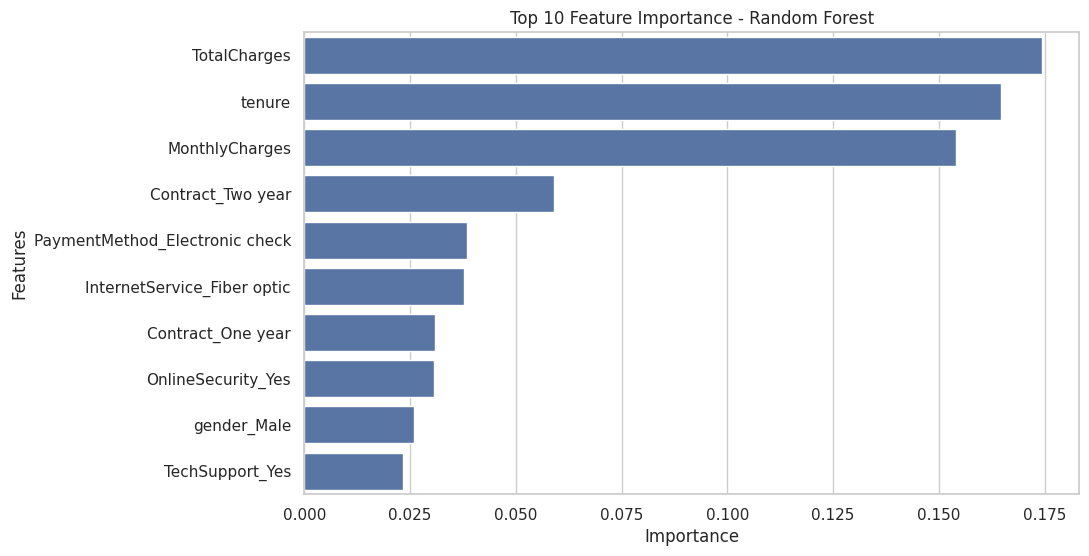

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Features')

plt.show()

**Conclusion**

# Conclusion générale – Customer Churn Prediction

Dans ce projet, nous avons réalisé une analyse et une prédiction du désabonnement des clients (*Customer Churn Prediction*) à partir d'un jeu de données contenant des informations sur les clients d'une entreprise de télécommunications.

Le travail a commencé par une phase de préparation des données (*Data Cleaning*), suivie d'une analyse exploratoire (*EDA*), de l'encodage des variables catégorielles et de la séparation des données en ensembles d'entraînement et de test.

Ensuite, nous avons développé et évalué deux modèles de Machine Learning :
- **Logistic Regression**
- **Random Forest**

Afin de mieux gérer le déséquilibre entre les classes, nous avons également utilisé `class_weight='balanced'`.

Les résultats montrent que le modèle **Logistic Regression avec class_weight='balanced'** obtient le meilleur Recall pour la classe Churn = 1, avec une valeur de **0.80 (80%)**. Ce résultat est particulièrement intéressant, car l'objectif principal est de détecter le maximum de clients susceptibles de résilier leur abonnement.

L'analyse de l'importance des variables (*Feature Importance*) avec Random Forest a également montré que `TotalCharges`, `tenure` et `MonthlyCharges` figurent parmi les variables les plus importantes pour les prédictions du modèle.

Enfin, ce projet nous a permis de comprendre l'importance du choix des métriques d'évaluation, notamment le Recall, ainsi que le rôle du Machine Learning dans l'identification des clients à risque de résiliation.

**Perspective :** améliorer les performances des modèles, tester d'autres techniques de gestion du déséquilibre des classes et proposer des stratégies de fidélisation adaptées aux clients à risque.